In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib
from matplotlib.colors import to_rgb

matplotlib.rc('xtick', labelsize=12)
matplotlib.rc('ytick', labelsize=12)

sns.set(style="whitegrid")

# -----------------------------
# LOAD DATA
# -----------------------------
df = pd.read_csv("metafile.csv", delimiter=",", low_memory=False)

info = pd.read_csv("participants_info.csv", delimiter=",")
info = (
    info[info["participant_id"].notna()]
    .drop_duplicates(subset="participant_id", keep="first")
    .copy()
)
info["pid"] = info["participant_id"].astype(str)

group_map = {
    0: "HC", 0.1: "HC Sibling", 1: "SSD", 1.1: "SCHZ Sibling",
    2: "BD", 3: "FEP", 4: "MDD", 5: "CHR", 6: "ADHD", 7: "PTSD",
    8: "GAD", 9: "SAD", 10: "SUD", 11: "OCD", 12: "SEAD",
    13: "ASD", 14: "CPS", 15: "Stroke", 16: "BPD", 17: "ARMS",
    18: "AN", 19: "WR", 20: "AUD", 21: "Panic Episode",
    22: "Agoraphobia",
}

info["group_split"] = info["group"].astype(str).str.split(";")
info_exp = info.explode("group_split")
info_exp["group_split"] = pd.to_numeric(
    info_exp["group_split"].str.strip(), errors="coerce"
)
info_exp["group_label"] = info_exp["group_split"].map(group_map)

group_totals = info_exp["group_label"].value_counts()
N_TOTAL = int(info["pid"].nunique())
print(f"Databank participants: {N_TOTAL}")

df["pid"] = df["participant_id"].astype(str)

# -----------------------------
# SCALES (item-level), across ALL participants
# -----------------------------
SANS_ITEMS = [f"sans_{i}" for i in range(1, 26)]
SAPS_ITEMS = [f"saps_{i}" for i in range(1, 35)]
PANSS_ITEMS = (
    [f"panss_p{i}" for i in range(1, 8)]
    + [f"panss_n{i}" for i in range(1, 8)]
    + [f"panss_g{i}" for i in range(1, 17)]
)
HAMD_ITEMS = [c for c in df.columns if c.startswith("hamilton_")]

def earliest_available(group_df, cols):
    """One value per participant: the first (earliest) non-null value
    found across their sessions, i.e. ANY-session rule at participant level."""
    sub = group_df[["pid"] + cols].copy()
    for c in cols:
        sub[c] = pd.to_numeric(sub[c], errors="coerce")
    return sub.groupby("pid", sort=False)[cols].first()

def summarize(clin):
    return pd.DataFrame({
        "n": clin.notna().sum(),
        "mean": clin.mean(),
        "q1": clin.quantile(0.25),
        "q3": clin.quantile(0.75),
    })

SCALES = {}

clin = earliest_available(df, PANSS_ITEMS)
SCALES["PANSS"] = {
    "summ": summarize(clin),
    "ids": set(clin.index[clin.notna().any(axis=1)]),
    "labels": [c.replace("panss_", "").upper() for c in clin.columns],
}

clin = earliest_available(df, HAMD_ITEMS).dropna(axis=1, how="all")
SCALES["HAM-D"] = {
    "summ": summarize(clin),
    "ids": set(clin.index[clin.notna().any(axis=1)]),
    "labels": [c.replace("hamilton_", "H") for c in clin.columns],
}

clin = earliest_available(df, SANS_ITEMS).dropna(axis=1, how="all")
SCALES["SANS"] = {
    "summ": summarize(clin),
    "ids": set(clin.index[clin.notna().any(axis=1)]),
    "labels": [c.replace("sans_", "SN") for c in clin.columns],
}

clin = earliest_available(df, SAPS_ITEMS).dropna(axis=1, how="all")
SCALES["SAPS"] = {
    "summ": summarize(clin),
    "ids": set(clin.index[clin.notna().any(axis=1)]),
    "labels": [c.replace("saps_", "SA") for c in clin.columns],
}

# -----------------------------
# AVAILABILITY BY DIAGNOSIS (all groups)
# -----------------------------
pid_groups = info_exp.dropna(subset=["group_label"]).groupby("pid")["group_label"].apply(list)

rows = []
avail = {}
for scale, s in SCALES.items():
    ids = s["ids"]
    ids_in_db = ids.intersection(set(pid_groups.index))
    per_group = {}
    for grp, tot in group_totals.items():
        n_with = sum(1 for pid in ids_in_db if grp in pid_groups[pid])
        if n_with > 0:
            per_group[grp] = (n_with, int(tot), n_with / tot * 100)
        rows.append({
            "scale": scale, "group": grp,
            "n_with_metric": n_with, "n_group": int(tot),
            "pct_of_group": round(n_with / tot * 100, 2),
        })
    s["avail"] = sorted(per_group.items(), key=lambda kv: -kv[1][0])
    s["total"] = len(ids_in_db)

avail_df = pd.DataFrame(rows)
avail_df.to_csv("metrics_availability.csv", index=False)

pd.set_option("display.max_rows", None)
print(avail_df.pivot(index="group", columns="scale",
                     values="pct_of_group").to_string())
print()
for scale, s in SCALES.items():
    print(f"{scale}: {s['total']} participants ({s['total'] / N_TOTAL * 100:.1f}% of databank)")

Databank participants: 8989


C:\Users\sergi\AppData\Local\Temp\ipykernel_37584\3892353430.py:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["pid"] = df["participant_id"].astype(str)


scale          HAM-D  PANSS   SANS   SAPS
group                                    
ADHD           13.35   1.24   0.31   0.31
AN              0.00   0.00   0.00   0.00
ARMS            0.00  73.08   1.92   0.00
ASD             0.00   0.00   0.00   0.00
AUD             0.00   0.00   0.00   0.00
Agoraphobia     0.00   0.00   0.00   0.00
BD             20.16   9.47  20.16  20.16
BPD             0.00   0.00   0.00   0.00
CHR             0.00   0.00   0.00   0.00
CPS             0.00   0.00   0.00   0.00
FEP             0.00  82.93   0.00   0.00
GAD             0.00   7.32   0.00   0.00
HC              0.00   1.60   1.58   1.58
HC Sibling      0.00   0.00  81.61  81.61
MDD             8.91   5.73   0.00   0.00
OCD             0.00   7.41   0.00   0.00
PTSD            0.00  28.57   0.00   0.00
Panic Episode   0.00   0.00   0.00   0.00
SAD             0.00  25.81   0.00   0.00
SCHZ Sibling    0.00   0.00  87.34  87.34
SEAD            0.00   0.00   0.00   0.00
SSD             3.60  30.50  38.86

In [29]:
# -----------------------------
# SHARED CIRCULAR-PLOT ROUTINE
# -----------------------------
def darken(hex_color, factor=0.62):
    r, g, b = to_rgb(hex_color)
    return (r * factor, g * factor, b * factor)

def circular_item_plot(summary, item_labels, colors, scale_name,
                       r_max, r_ticks, filename,
                       legend_handles=None):
    """Publication-ready circular plot:
       radial bars = mean item score, capped error bars = IQR (Q1-Q3) in a
       darker, semi-transparent shade of the bar colour; radial limit set to
       the next integer above the largest value."""
    n_items = len(summary)
    theta = np.deg2rad(90 - np.arange(n_items) * 360.0 / n_items)

    means = summary["mean"].values
    q1s = summary["q1"].values
    q3s = summary["q3"].values

    lo_all = np.minimum(means, q1s)
    hi_all = np.maximum(means, q3s)

    # Adapt radial limits to the plotted values
    r_max = int(np.ceil(hi_all.max()))
    r_ticks = list(range(1, r_max + 1))

    fig = plt.figure(figsize=(9, 9))
    ax = fig.add_subplot(111, polar=True)
    ax.set_facecolor("white")

    width = np.deg2rad(360.0 / n_items) * 0.72

    for t, m, q1, q3, col in zip(theta, means, q1s, q3s, colors):
        ax.bar(t, m, width=width, bottom=0.0, color=col,
               edgecolor="white", linewidth=0.8, alpha=0.85, zorder=3)
        lo = min(m, q1)
        hi = max(m, q3)
        ax.errorbar(t, m, yerr=[[m - lo], [hi - m]], fmt="none",
                    ecolor=darken(col), elinewidth=1.3, capsize=2.5,
                    capthick=1.3, alpha=0.6, zorder=4)

    # Single ring of item labels
    r_lab = r_max * 1.06
    for t, name in zip(theta, item_labels):
        deg = np.rad2deg(t) % 360
        rot = deg - 90
        left_side = 90 < deg <= 270
        if left_side:
            rot -= 180
        ax.text(t, r_lab, f"{name}", rotation=rot,
                rotation_mode="anchor", ha="center",
                va="bottom" if not left_side else "top",
                fontsize=15, color="#2B2B2B", linespacing=1.3)

    # Frame and grid
    ax.set_ylim(0, r_max)
    ax.set_yticks(r_ticks)
    ax.set_yticklabels([f"{r:g}" for r in r_ticks], fontsize=13, color="#555555")
    ax.set_rlabel_position(90 + 180.0 / n_items)
    ax.set_xticks([])  # remove the degree labels
    ax.grid(color="#CCCCCC", linewidth=0.8, alpha=0.9)
    ax.tick_params(axis="x", length=0)
    spine_key = "polar" if "polar" in ax.spines else "circle"
    ax.spines[spine_key].set_visible(False)
    ax.yaxis.grid(True)
    ax.xaxis.grid(False)

    # Center annotation
    ax.text(0, 0, scale_name, ha="center", va="center",
            fontsize=26, fontweight="bold", color="#2B2B2B")

    if legend_handles is not None:
        ax.legend(handles=legend_handles, loc="lower center",
                  bbox_to_anchor=(0.05, -0.12), ncol=1,
                  frameon=False, fontsize=15)

    plt.tight_layout()
    plt.savefig(filename, format="pdf", bbox_inches="tight")
    plt.show()

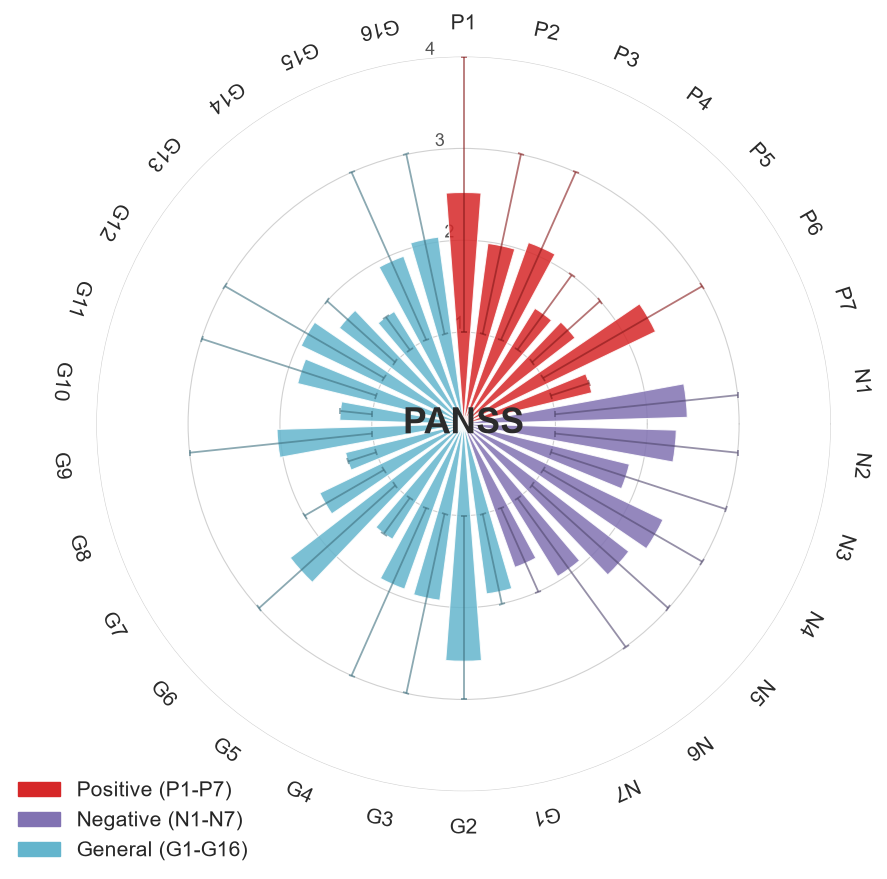

In [30]:
# -----------------------------
# PANEL 1 - PANSS (all participants)
# -----------------------------
panss_colors = {"p": "#D62728", "n": "#8172B2", "g": "#64B5CD"}
panss_names = {"p": "Positive (P1-P7)", "n": "Negative (N1-N7)",
               "g": "General (G1-G16)"}

s = SCALES["PANSS"]
colors_a = [panss_colors[c.split("_")[1][0]] for c in s["summ"].index]

legend_a = [matplotlib.patches.Patch(color=panss_colors[k], label=panss_names[k])
            for k in ["p", "n", "g"]]

circular_item_plot(
    s["summ"], s["labels"], colors_a, "PANSS",
    r_max=5, r_ticks=[1, 2, 3, 4, 5],
    filename="figB1.pdf",
    legend_handles=legend_a,
)

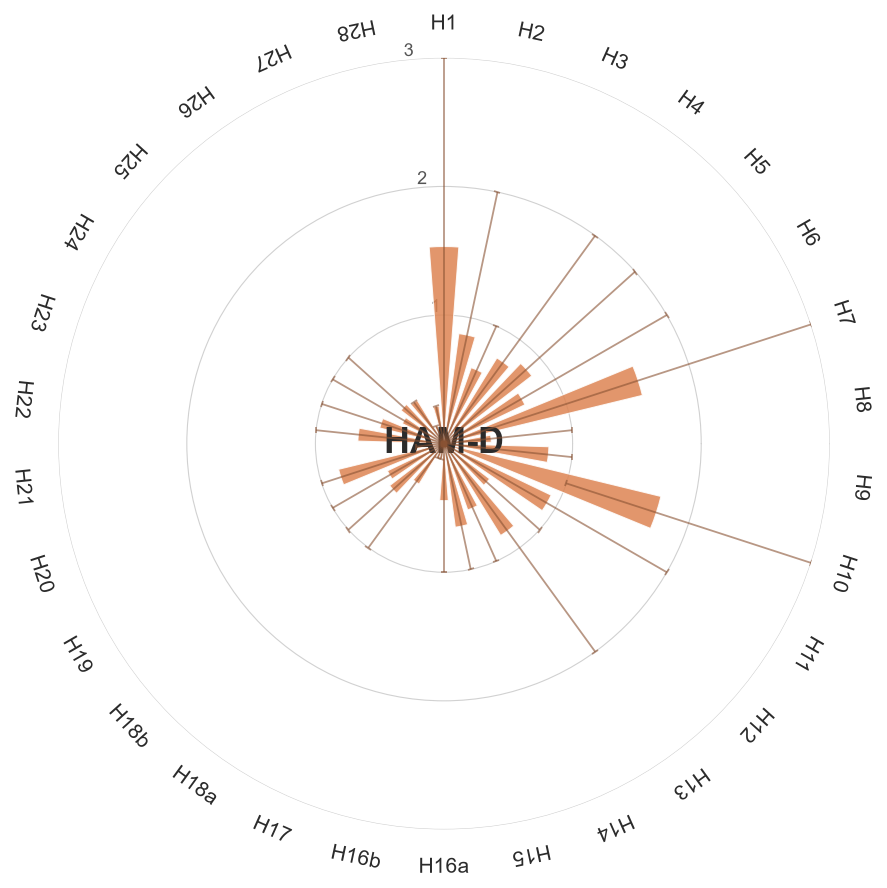

In [4]:
# -----------------------------
# PANEL 2 - HAM-D (all participants)
# -----------------------------
s = SCALES["HAM-D"]

circular_item_plot(
    s["summ"], s["labels"], ["#DD8452"] * len(s["summ"]), "HAM-D",
    r_max=5.6, r_ticks=[1, 2, 3, 4, 5],
    filename="figB2.pdf",
    legend_handles=None,
)

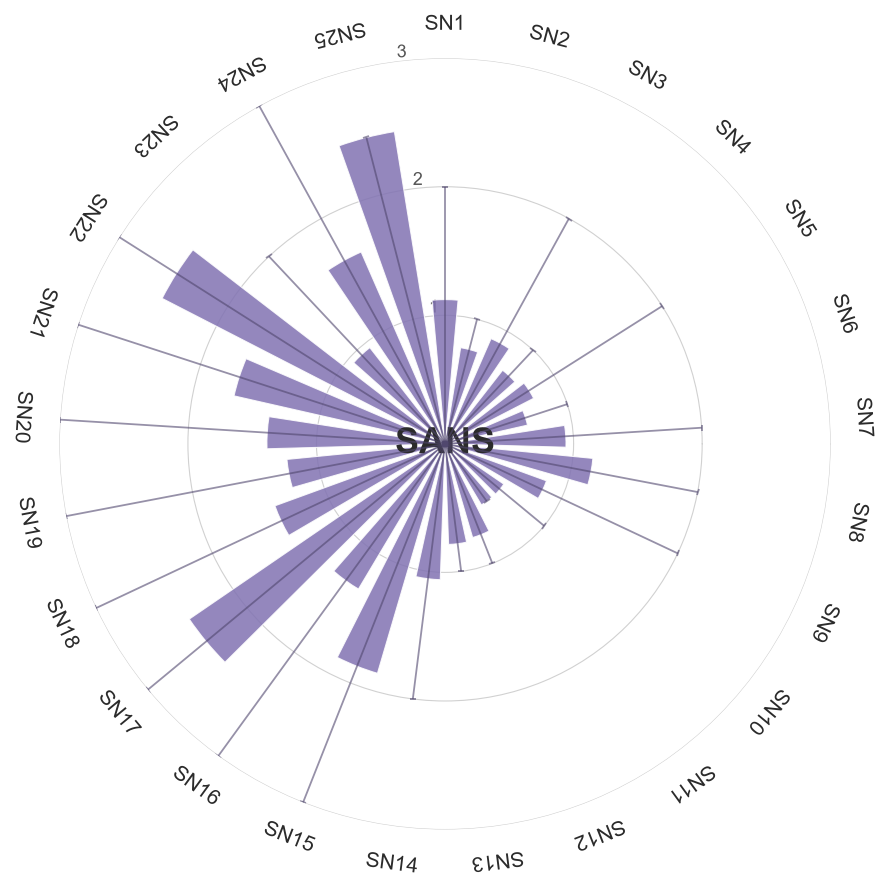

In [5]:
# -----------------------------
# PANEL 3 - SANS (all participants)
# -----------------------------
s = SCALES["SANS"]

circular_item_plot(
    s["summ"], s["labels"], ["#8172B2"] * len(s["summ"]), "SANS",
    r_max=6, r_ticks=[1, 2, 3, 4, 5, 6],
    filename="figB3.pdf",
    legend_handles=None,
)

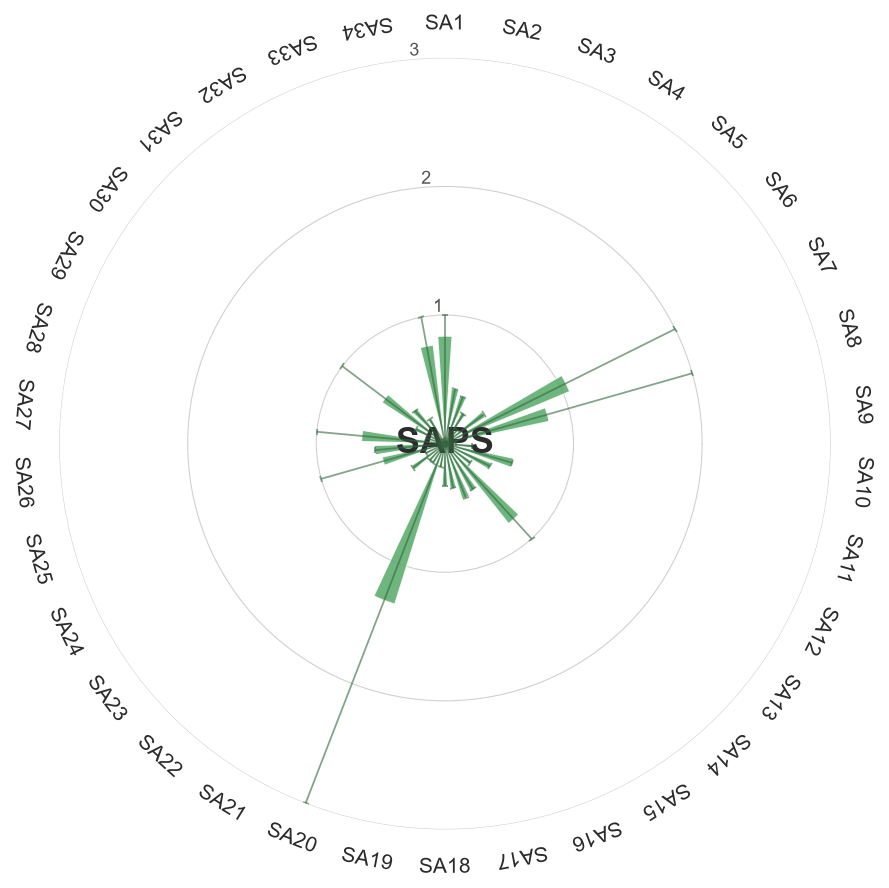

PANSS: n = 699 (7.8% of databank, N = 8989)
----------------------------------------------
  SSD              30.5%  (423/1387)
  HC                1.6%  (81/5071)
  MDD               5.7%  (45/786)
  ARMS             73.1%  (38/52)
  FEP              82.9%  (34/41)
  BD                9.5%  (23/243)
  GAD               7.3%  (18/246)
  PTSD             28.6%  (14/49)
  SUD               7.2%  (9/125)
  SAD              25.8%  (8/31)
  ADHD              1.2%  (4/322)
  OCD               7.4%  (2/27)

HAM-D: n = 212 (2.4% of databank, N = 8989)
----------------------------------------------
  MDD               8.9%  (70/786)
  SSD               3.6%  (50/1387)
  BD               20.2%  (49/243)
  ADHD             13.4%  (43/322)

SANS: n = 810 (9.0% of databank, N = 8989)
----------------------------------------------
  SSD              38.9%  (539/1387)
  HC                1.6%  (80/5071)
  HC Sibling       81.6%  (71/87)
  SCHZ Sibling     87.3%  (69/79)
  BD               20.2%  (49/

In [6]:
# -----------------------------
# PANEL 4 - SAPS (all participants)
# -----------------------------
s = SCALES["SAPS"]

circular_item_plot(
    s["summ"], s["labels"], ["#55A868"] * len(s["summ"]), "SAPS",
    r_max=6, r_ticks=[1, 2, 3, 4, 5, 6],
    filename="figB4.pdf",
    legend_handles=None,
)

# -----------------------------
# REPORT: availability per scale and diagnosis
# -----------------------------
for scale, s in SCALES.items():
    print("=" * 46)
    print(f"{scale}: n = {s['total']} "
          f"({s['total'] / N_TOTAL * 100:.1f}% of databank, N = {N_TOTAL})")
    print("-" * 46)
    for grp, (k, tot, pct) in s["avail"]:
        print(f"  {grp:<15} {pct:>5.1f}%  ({k}/{tot})")
    print()